# 11 · Reinvestment and capital mobility

Notebook 10 estimated the capital-mobility coefficient `μ` between the sectors of 26 EU countries and found it negative, `μ̂` ≈ −0.14. Its decomposition traced the sign to an assumption of the model rather than to capital fleeing profit: every department reinvests a fixed share `σ_c` of its own surplus, while in the data net investment rises with the profit-rate gap much less than the surplus does.

The model now lets the reinvestment share fall with relative profitability (`simulate_Ndept_custom(...; η)`, `_reinvestment_share`):

`investmentᵢ = σ_c,ᵢ · (r̄/rᵢ)^η · Sᵢ + μ · (rᵢ − r̄) · Cᵢ`,

with `η = 0` the fixed share and `η = 1` investment proportional to capital at the average profit rate, own surplus no longer mattering. This notebook takes that investment function to the same panel: how far does the data pin down `η`, and what is `μ` once reinvestment is allowed to depart from a fixed share? `compute_investment_panel` and `estimate_investment_function` (`src/mobility_estimation.jl`) do the work.

In [1]:
include(joinpath("..", "..", "src", "MarxKapital.jl"))
using Plots, DataFrames, Statistics, LinearAlgebra, Random, Printf
gr(fmt = :png, size = (760, 420), margin = 3Plots.mm)

MarxKapital loaded. Type  model_help()  to get started.


Plots.GRBackend()

In [2]:
"""K-weighted dispersion of the profit rates along a simulated path."""
function dispersion_path(sol, p)
    N = length(p.e)
    map(sol.u) do X
        C, V = X[1:N], X[N+1:2N]
        r = _io_profit_rates(C, V, p.e .* V, p)
        r̄ = sum(r .* C) / sum(C)
        sqrt(sum(C .* (r .- r̄) .^ 2) / sum(C))
    end
end

dispersion_path (generic function with 1 method)

## 1. The panel, and where notebook 10 left off

The 15 market sectors of 26 EU countries (`data/eurostat_eu_sectors.csv`). The investment function is written in gross terms, as in the model, where depreciation enters separately as `δC`: the dependent variable is the gross investment rate `gk = 100·GFCFₜ/Cₜ₋₁`, the surplus term uses `sk = 100·Sₜ/Cₜ₋₁` and each country × sector's gross reinvestment share `σ̄ᵢ = ΣGFCF/ΣS` (the data's `σ_c`), and the profit rates are those of `t−1`, as in notebook 10. Rows with a non-positive surplus or profit rate cannot enter `(r̄/r)^η` and are dropped.

In [3]:
eu = CSV.read(joinpath("..", "..", "data", "eurostat_eu_sectors.csv"), DataFrame)
ALL = sort(String.(unique(eu.section)))
MARKET = setdiff(ALL, ["L", "O", "P", "Q"])
IP = compute_investment_panel(eu; sections = MARKET)
fixed = estimate_mobility(IP)
@printf("%d observations, %d usable for the investment function\n", nrow(IP), count(IP.valid))
@printf("notebook 10, fixed reinvestment share: μ̂ = %.3f (clustered se %.3f)\n", fixed.μ, fixed.se_cluster)

10665 observations, 9891 usable for the investment function
notebook 10, fixed reinvestment share: μ̂ = -0.138 (clustered se 0.044)


## 2. The investment function, `η` by `η`

`estimate_investment_function` fits

`gk = λ · σ̄ᵢ · (r̄/rᵢ)^η · sk + μ · gap + country × sector + country × year effects`

for each `η` on a grid. `λ` scales the reinvestment term: `λ = 1` is the model's own level, where each department reinvests its share `σ_c` of its surplus. First on every usable row, then trimming the years in which a sector's profit rate is below a third or above three times its country's average.

In [4]:
full = estimate_investment_function(IP)
trim = estimate_investment_function(IP; ratio_bounds = (1/3, 3))
println("all usable rows ($(full.n)):")
show(select(full.profile, :η, :λ, :μ, :se_μ, :ssr)[[1, 2, 3, 6, 11], :]; summary = false, eltypes = false)
println("\n\nr/r̄ between 1/3 and 3 ($(trim.n) rows):")
show(select(trim.profile, :η, :λ, :se_λ, :μ, :se_μ, :ssr); summary = false, eltypes = false)

all usable rows (9891):


 Row │ η    λ           μ          se_μ        ssr       
─────┼───────────────────────────────────────────────────
   1 │ 0.0  0.119783    0.0538325  0.0101568   1.88057e5
   2 │ 0.1  0.116493    0.0646576  0.00970779  1.88368e5
   3 │ 0.2  0.00148075  0.106873   0.0130712   1.91674e5
   4 │ 0.5  1.01702e-8  0.107218   0.0131745   1.91726e5
   5 │ 1.0  1.4914e-16  0.107205   0.0131758   1.91726e5

r/r̄ between 1/3 and 3 (7580 rows):


 Row │ η    λ          se_λ       μ          se_μ       ssr            
─────┼─────────────────────────────────────────────────────────────────
   1 │ 0.0  0.116799   0.0267907  0.0455847  0.0327748       1.38805e5
   2 │ 0.1  0.119009   0.026958   0.0545637  0.0335607       1.38903e5
   3 │ 0.2  0.11968    0.0270736  0.0641459  0.0343784       1.3902e5
   4 │ 0.3  0.118456   0.0271554  0.0741492  0.0351709       1.39157e5
   5 │ 0.4  0.115008   0.027212   0.0843056  0.0358839       1.39312e5
   6 │ 0.5  0.109113   0.0272284  0.0942534  0.0364741       1.39483e5
   7 │ 0.6  0.100747   0.0271531  0.103556   0.0369176       1.39665e5
   8 │ 0.7  0.0901728  0.0268968  0.111757   0.0372149       1.39849e5
   9 │ 0.8  0.0779611  0.0263546  0.118462   0.0373864  140027.0
  10 │ 0.9  0.0649266  0.0254465  0.123433   0.0374616       1.40189e5
  11 │ 1.0  0.0519693  0.0241538  0.126639   0.037466        1.40327e5

**On every row, the term breaks down as soon as `η` > 0.1**: in the years a sector's profit rate is barely positive, `(r̄/r)^η` explodes, a handful of observations dominate the regressor, `λ` collapses to zero and the fit is that of the mobility term alone (`μ̂` = 0.107). Trimming those years is necessary for the function to say anything.

**On the trimmed sample, three things stand out.**

- **`λ` is far below 1**, about 0.12 at `η` = 0 and 0.05 at `η` = 1: within a sector, investment follows its own surplus at a tenth of the average reinvestment share or less.
- **The fit barely depends on `η`**: the residual sum of squares rises by 1.1% from `η` = 0 to `η` = 1. The panel does not identify `η` by itself.
- **`μ̂` is positive for every `η`**, and rises with it: 0.05 at `η` = 0, 0.09 at 0.5, 0.13 at 1.

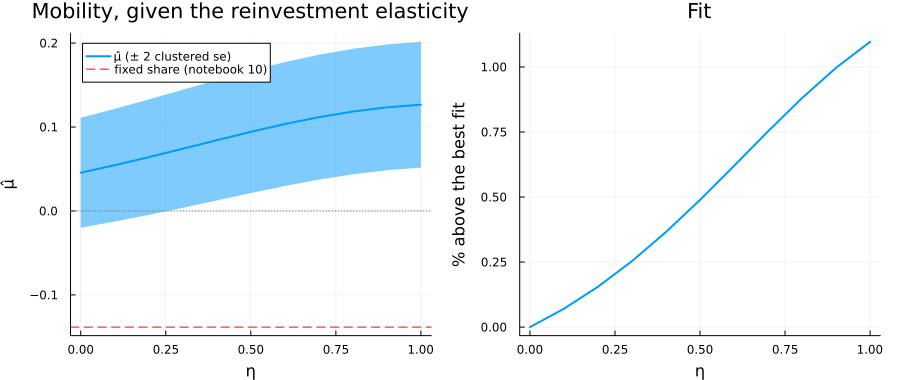

In [5]:
pr = trim.profile
p1 = plot(pr.η, pr.μ, ribbon = 2 .* pr.se_μ, lw = 2, label = "μ̂ (± 2 clustered se)", xlabel = "η",
          ylabel = "μ̂", legend = :topleft, title = "Mobility, given the reinvestment elasticity")
hline!(p1, [fixed.μ], ls = :dash, color = :red, label = "fixed share (notebook 10)")
hline!(p1, [0], color = :gray, ls = :dot, label = "")
p2 = plot(pr.η, 100 .* (pr.ssr ./ minimum(pr.ssr) .- 1), lw = 2, legend = false, xlabel = "η",
          ylabel = "% above the best fit", title = "Fit")
plot(p1, p2, layout = (1, 2), size = (900, 380))

## 3. The model's own level

What if the model's level is imposed, `λ = 1`, so that `η` alone has to absorb how little investment follows own surplus?

In [6]:
Q = IP[IP.valid .& (1/3 .<= IP.r ./ IP.rbar .<= 3), :]
for η in (0.0, 0.5, 1.0)
    e = estimate_fe_ols(Q, Q.gk .- Q.σbar .* (Q.rbar ./ Q.r) .^ η .* Q.sk, Q.gap)
    @printf("λ = 1, η = %.1f:  μ̂ = %6.3f (clustered se %.3f)   fit %5.1f%% worse than with λ free\n",
            η, e.β[1], e.se_cluster[1], 100 * (e.ssr / minimum(trim.profile.ssr) - 1))
end

λ = 1, η = 0.0:  μ̂ = -0.534 (clustered se 0.073)   fit  76.5% worse than with λ free
λ = 1, η = 0.5:  μ̂ = -0.134 (clustered se 0.043)   fit  57.1% worse than with λ free


λ = 1, η = 1.0:  μ̂ =  0.208 (clustered se 0.051)   fit  81.5% worse than with λ free


**With the model's level imposed, the fit is 57–82% worse** than with `λ` free, and `μ̂` swings from −0.53 to 0.21 with `η`. The panel rejects the level: no single elasticity makes a department's investment follow its own surplus as weakly as it does in the data while keeping its average share. The model's investment function, in other words, is right about the average share and wrong about the margin.

## 4. Calibrating `η`, and `μ` at it

What the panel does pin down is the margin: investment follows own surplus at about a tenth of the average share (`λ` ≈ 0.1 with `η` = 0). In the model, at `r = r̄`, the marginal share of `σ_c·(r̄/r)^η·S` is `(1 − η)·σ_c`, so a margin of a tenth of the average corresponds to **`η` ≈ 0.9**. We calibrate **`η` = 1** and read `μ` off at it, on the trimmed sample:

In [7]:
at1(P) = estimate_investment_function(P; η_grid = [1.0], ratio_bounds = (1/3, 3)).profile[1, :]
checks = [("baseline", IP),
          ("self-employed imputed", compute_investment_panel(eu; sections = MARKET, self_employed = :imputed)),
          ("without IE and LU", IP[.!in.(IP.geo, Ref(["IE", "LU"])), :]),
          ("1997-2008", IP[(IP.year .>= 1997) .& (IP.year .<= 2008), :]),
          ("2009 onwards", IP[IP.year .> 2008, :]),
          ("all 19 sections", compute_investment_panel(eu; sections = ALL))]
for (lab, P) in checks
    r = at1(P)
    @printf("%-24s μ̂ = %5.3f  (clustered se %.3f, Driscoll-Kraay %.3f)   λ = %.3f\n", lab, r.μ, r.se_μ, r.se_DK_μ, r.λ)
end
μ_cal = round(at1(IP).μ, digits = 2)

baseline                 μ̂ = 0.127  (clustered se 0.037, Driscoll-Kraay 0.027)   λ = 0.052
self-employed imputed    μ̂ = 0.148  (clustered se 0.024, Driscoll-Kraay 0.023)   λ = 0.040


without IE and LU        μ̂ = 0.110  (clustered se 0.038, Driscoll-Kraay 0.034)   λ = 0.071
1997-2008                μ̂ = 0.067  (clustered se 0.061, Driscoll-Kraay 0.033)   λ = 0.044


2009 onwards             μ̂ = 0.199  (clustered se 0.046, Driscoll-Kraay 0.038)   λ = 0.082
all 19 sections          μ̂ = 0.289  (clustered se 0.049, Driscoll-Kraay 0.014)   λ = 0.102


0.13

**At `η` = 1, `μ̂` = 0.13** (clustered error 0.04), and it stays positive in every check: 0.11 without Ireland and Luxembourg, 0.15 with the self-employed imputed, 0.07 up to 2008 and 0.20 after, and 0.29 with the four non-market sections included. Once a department's reinvestment is allowed to follow its own surplus as weakly as the data say, capital does move toward the sectors with the higher profit rate, at somewhat less than half the model's default speed (0.3) and below the between-country estimate of notebook 8 (0.22).

## 5. 2008, again

Notebook 10 found that the share of surplus reinvested *net of depreciation* halved after 2008 and that this, not `μ`, made the mobility estimate move. The model's `σ_c` is a gross share (depreciation is `δC`), so the question for a `σ_schedule` is whether the *gross* share changed too:

In [8]:
m = eu[in.(eu.section, Ref(MARKET)) .& (eu.year .>= 1997), :]
m.S = m.GVA .- m.compensation .- m.CFC
cy = combine(groupby(m, [:geo, :year]),
             [:GFCF, :S] => ((g, s) -> sum(g) / sum(s)) => :gross,
             [:GFCF, :CFC, :S] => ((g, c, s) -> sum(g .- c) / sum(s)) => :net,
             [:CFC, :S] => ((c, s) -> sum(c) / sum(s)) => :depreciation)
for col in (:gross, :net, :depreciation)
    @printf("%-13s / surplus, mean over countries:  1997-2008 %.3f   2009 onwards %.3f\n", col,
            mean(cy[cy.year .<= 2008, col]), mean(cy[cy.year .> 2008, col]))
end

gross         / surplus, mean over countries:  1997-2008 0.692   2009 onwards 0.706
net           / surplus, mean over countries:  1997-2008 0.188   2009 onwards 0.101


depreciation  / surplus, mean over countries:  1997-2008 0.504   2009 onwards 0.605


**The gross share did not change** (0.69 before, 0.71 after). What changed is depreciation, from half of the surplus to 0.61 of it, and with it the net share. In the model's terms the break at 2008 is in `δ` relative to `S`, not in `σ_c`, so the data do not call for a `σ_schedule` on `σ_c`. The option stays available for scenarios.

## 6. Back in the model

Portugal's 15 market sectors in 2019, as in notebooks 9 and 10, but now with each sector's own gross reinvestment share `σ̄ᵢ` as its `σ_c` (capped at 0.85, with `σ_v` = 0.1: five sectors invested more than their surplus over the period, which a `Department` cannot represent). The calibrations: the fixed share with notebook 10's `μ̂` and with the default `μ` = 0.3, and `η` = 0, 0.5 and 1 with the `μ̂` the trimmed profile gives at each. For each, the dispersion of profit rates, the largest sector's share of constant capital and the lowest profit rate, over 40 years.

fixed share, notebook 10   η = 0.0 μ = -0.14  t = 20: dispersion 0.0309, largest share 1.00 (D), lowest r 0.0057
fixed share, notebook 10   η = 0.0 μ = -0.14  t = 40: dispersion 0.0004, largest share 1.00 (D), lowest r 0.0038


fixed share, default μ     η = 0.0 μ =  0.30  t = 20: dispersion 0.0147, largest share 1.00 (D), lowest r 0.0291
fixed share, default μ     η = 0.0 μ =  0.30  t = 40: dispersion 0.0002, largest share 1.00 (D), lowest r 0.0297
η = 0, profile             η = 0.0 μ =  0.05  t = 20: dispersion 0.0206, largest share 1.00 (D), lowest r 0.0151
η = 0, profile             η = 0.0 μ =  0.05  t = 40: dispersion 0.0002, largest share 1.00 (D), lowest r 0.0162
η = 0.5, profile           η = 0.5 μ =  0.09  t = 20: dispersion 0.0439, largest share 0.99 (D), lowest r 0.0009
η = 0.5, profile           η = 0.5 μ =  0.09  t = 40: dispersion 0.0006, largest share 1.00 (D), lowest r 0.0006


η = 1, calibrated          η = 1.0 μ =  0.13  t = 20: dispersion 0.7134, largest share 0.95 (B), lowest r 0.0000
η = 1, calibrated          η = 1.0 μ =  0.13  t = 40: dispersion 0.7187, largest share 0.96 (B), lowest r 0.0000


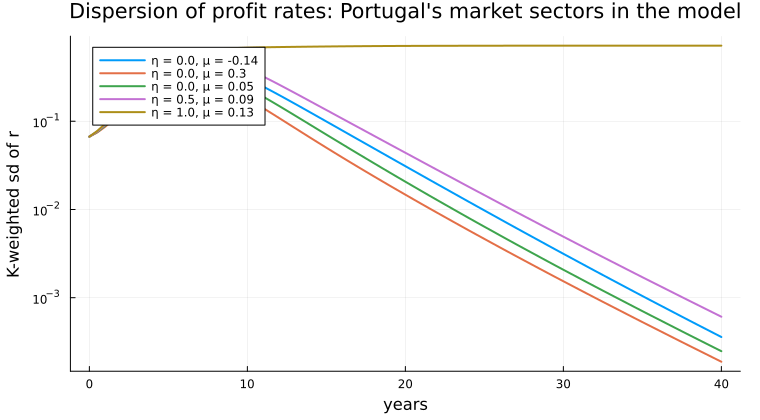

In [9]:
P19 = eu[(eu.geo .== "PT") .& (eu.year .== 2019), :]
σbar_pt = Dict(zip(IP.section[IP.geo .== "PT"], IP.σbar[IP.geo .== "PT"]))
depts = map(MARKET) do s
    row = P19[P19.section .== s, :][1, :]
    S = row.GVA - row.compensation - row.CFC
    Department(String(s); c = row.capital_stock, v = row.compensation, e = max(S / row.compensation, 0.1),
               σ_c = min(σbar_pt[s], 0.85), σ_v = 0.1, δ = row.CFC / row.capital_stock)
end
μ_at(η) = round(trim.profile.μ[findfirst(≈(η), trim.profile.η)], digits = 2)
runs = [(0.0, round(fixed.μ, digits = 2), "fixed share, notebook 10"), (0.0, 0.3, "fixed share, default μ"),
        (0.0, μ_at(0.0), "η = 0, profile"), (0.5, μ_at(0.5), "η = 0.5, profile"), (1.0, μ_at(1.0), "η = 1, calibrated")]
plt = plot(xlabel = "years", ylabel = "K-weighted sd of r", legend = :topleft, yscale = :log10,
           title = "Dispersion of profit rates: Portugal's market sectors in the model")
for (η, μ, lab) in runs
    sol, _, p = simulate_Ndept_custom(deepcopy(depts); T = 40.0, seed = 1, coupled = true, μ = μ, η = η)
    d = dispersion_path(sol, p)
    plot!(plt, sol.t, d, lw = 2, label = "η = $η, μ = $μ")
    for t in (20.0, 40.0)
        X = sol.u[findfirst(>=(t), sol.t)]
        C, V = X[1:15], X[16:30]
        r = _io_profit_rates(C, V, p.e .* V, p)
        k = argmax(C)
        @printf("%-26s η = %.1f μ = %5.2f  t = %2d: dispersion %.4f, largest share %.2f (%s), lowest r %.4f\n",
                lab, η, μ, t, d[findfirst(>=(t), sol.t)], C[k] / sum(C), MARKET[k], minimum(r))
    end
end
plt

**Under every calibration the model piles constant capital into one sector**, and this has nothing to do with the reinvestment function. With a fixed share, or with `η` = 0.5, energy (D, whose rate of exploitation in 2019 was 5.6, far above every other sector's) holds essentially all of it by year 20, so the falling dispersion measures the disappearance of the other sectors, not the convergence of their profit rates. The coupled model without market prices has no interior balanced growth (`src/growth.jl`): nothing reallocates variable capital, and the fastest-growing department takes over. Notebooks 9 and 10 reported the same falling dispersion and should be read the same way.

**With `η` = 1 it is worse.** A sector's investment no longer reacts to its own profit rate, so the least profitable sectors keep accumulating at the average rate while their profit rate falls to zero: mining (B) ends up with 95% of constant capital, the lowest profit rate is 0 and the dispersion stays at 0.71. The mobility term at `μ` = 0.13 does not hold this back. The investment function the data support therefore needs something the model lacks: a way for capital to leave unprofitable sectors other than through `μ` (scrapping, or a reinvestment share that does not stay so flat when the profit rate collapses), and an economy with interior balanced growth to study it in. The cross-dual system has that, but its profits at market prices can be negative, so it does not support `η` yet.

## What the panel says about reinvestment and mobility

- **With a fixed reinvestment share, `μ̂` = −0.14** (notebook 10). **Once reinvestment is allowed to depart from it, `μ̂` is positive** for every elasticity on the trimmed sample, from 0.05 at `η` = 0 to 0.13 at `η` = 1.
- **The panel does not identify `η`.** The fit changes by 1.1% between `η` = 0 and 1. What it pins down is that investment follows a sector's own surplus at about a tenth of the average reinvestment share (`λ` ≈ 0.05–0.12); the model's own level (`λ` = 1) fits 57–82% worse.
- **Calibrating `η` = 1** (a marginal share of `(1 − η)·σ_c` ≈ a tenth of the average implies `η` ≈ 0.9) gives **`μ̂` = 0.13** (clustered error 0.04), positive in every check (0.07 to 0.29): capital does move toward the higher profit rate, at less than half the model's default.
- **The break at 2008 is in depreciation, not in `σ_c`.** The gross reinvestment share was unchanged (0.69, 0.71); the net share halved because depreciation rose from 0.50 to 0.61 of the surplus. No `σ_schedule` is needed.
- **In the model, `η` = 1 with `μ` = 0.13 is not stable** for Portugal's sectors: unprofitable sectors accumulate until their profit rate reaches zero. The next steps are `η` in the cross-dual system and an exit for unprofitable capital.